In [1]:

# Import libraries for our Fake News Detection project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning tools
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load both datasets
fake_df = pd.read_csv("Fake.csv")
true_df = pd.read_csv("True.csv")

# Display the number of articles
print("Fake news articles:", len(fake_df))
print("Real news articles:", len(true_df))

# Display dataset columns
print("\nDataset columns:")
print(fake_df.columns.tolist())

# Preview the first 5 fake news articles
fake_df.head()


Fake news articles: 23481
Real news articles: 21417

Dataset columns:
['title', 'text', 'subject', 'date']


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [3]:

# Assign labels
fake_df["label"] = 0
true_df["label"] = 1

# Combine both datasets
df = pd.concat([fake_df, true_df], ignore_index=True)

# Shuffle the dataset randomly
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Check the combined dataset
print("Total articles:", len(df))

print("\nLabel distribution:")
print(df["label"].value_counts())

# Preview the dataset
df.head()


Total articles: 44898

Label distribution:
label
0    23481
1    21417
Name: count, dtype: int64


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [4]:

import re

# Function to clean news text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Remove rows with missing or empty article text
df = df.dropna(subset=["text"]).copy()
df = df[df["text"].str.strip() != ""].copy()

# Clean article text
df["clean_text"] = df["text"].apply(clean_text)

# Remove articles that become empty after cleaning
df = df[df["clean_text"] != ""].copy()

# Display original and cleaned text
print("Original article:")
print(df["text"].iloc[0][:300])

print("\nCleaned article:")
print(df["clean_text"].iloc[0][:300])

print("\nRemaining articles:", len(df))


Original article:
21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame appearing in TV shows and films such as Ferris Bueller s Day Off) made some provocative statements on Judge Jeanine Pirro s show recently. While discussing the halt that was imposed on Pres

Cleaned article:
st century wire says ben stein reputable professor from pepperdine university also of some hollywood fame appearing in tv shows and films such as ferris bueller s day off made some provocative statements on judge jeanine pirro s show recently while discussing the halt that was imposed on president t

Remaining articles: 44183


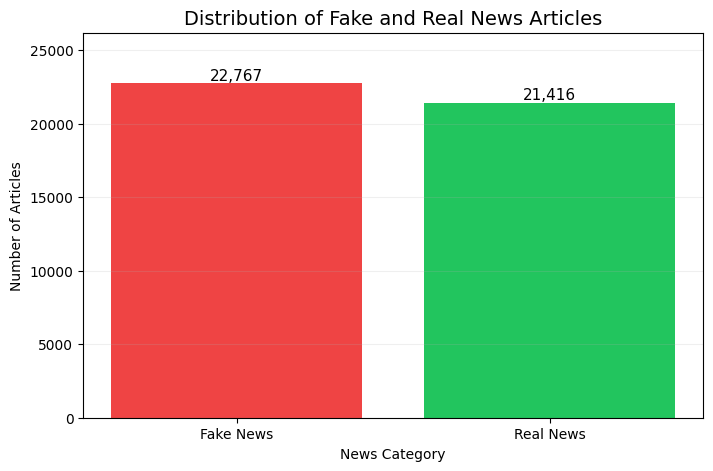

In [5]:

# Count articles in each category
news_counts = df["label"].value_counts().sort_index()

# Create a bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Fake News", "Real News"],
    [news_counts[0], news_counts[1]],
    color=["#ef4444", "#22c55e"]
)

# Add numbers above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 200,
        f"{int(bar.get_height()):,}",
        ha="center",
        fontsize=11
    )

plt.title("Distribution of Fake and Real News Articles", fontsize=14)
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.ylim(0, max(news_counts) * 1.15)
plt.grid(axis="y", alpha=0.2)

plt.savefig("news_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


In [6]:

# Select the cleaned news text and labels
X = df["clean_text"]
y = df["label"]

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the number of articles
print("Training articles:", len(X_train))
print("Testing articles:", len(X_test))
print("Total articles:", len(X_train) + len(X_test))


Training articles: 35346
Testing articles: 8837
Total articles: 44183


In [10]:

# Faster TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 1),
    max_df=0.95,
    min_df=2
)

# Convert training and testing text into numbers
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")
print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)


TF-IDF conversion completed!
Training matrix: (35346, 5000)
Testing matrix: (8837, 5000)


In [11]:

# Train Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

# Make predictions on testing data
lr_predictions = lr_model.predict(X_test_tfidf)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression trained successfully!")
print(f"Accuracy: {lr_accuracy * 100:.2f}%")


Logistic Regression trained successfully!
Accuracy: 98.74%


In [12]:

# Train Naive Bayes model
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

# Predict test articles
nb_predictions = nb_model.predict(X_test_tfidf)

# Calculate accuracy
nb_accuracy = accuracy_score(y_test, nb_predictions)

# Compare both models
print("Model Comparison")
print("--------------------------")
print(f"Logistic Regression: {lr_accuracy * 100:.2f}%")
print(f"Naive Bayes:         {nb_accuracy * 100:.2f}%")


Model Comparison
--------------------------
Logistic Regression: 98.74%
Naive Bayes:         92.80%


In [13]:

# Detailed evaluation of Logistic Regression
print("Logistic Regression Classification Report")
print("-----------------------------------------")

print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Fake News", "Real News"]
))


Logistic Regression Classification Report
-----------------------------------------
              precision    recall  f1-score   support

   Fake News       0.99      0.98      0.99      4554
   Real News       0.98      0.99      0.99      4283

    accuracy                           0.99      8837
   macro avg       0.99      0.99      0.99      8837
weighted avg       0.99      0.99      0.99      8837



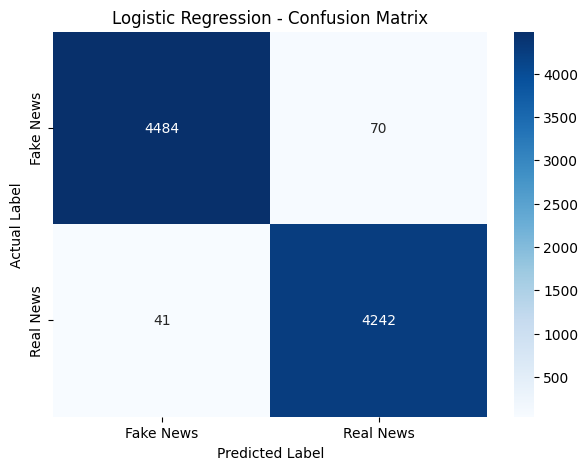

In [14]:

# Create confusion matrix
cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News", "Real News"],
    yticklabels=["Fake News", "Real News"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


In [15]:

# Check duplicate articles in the full dataset
duplicates = df["clean_text"].duplicated().sum()

print("Total articles:", len(df))
print("Duplicate articles:", duplicates)

# Check if training and testing contain identical articles
train_texts = set(X_train)
test_texts = set(X_test)

overlap = train_texts.intersection(test_texts)

print("Unique articles appearing in both training and testing:", len(overlap))


Total articles: 44183
Duplicate articles: 5870
Unique articles appearing in both training and testing: 1826


In [16]:

# Remove duplicate articles before splitting
df = df.drop_duplicates(subset=["clean_text"]).copy()

# Check whether identical text has conflicting labels
conflicts = (
    df.groupby("clean_text")["label"]
    .nunique()
    .gt(1)
    .sum()
)

print("Articles after removing duplicates:", len(df))
print("Conflicting labels remaining:", conflicts)

# Create new training and testing sets
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check for overlap
overlap = set(X_train).intersection(set(X_test))

print("Training articles:", len(X_train))
print("Testing articles:", len(X_test))
print("Training/testing overlap:", len(overlap))


Articles after removing duplicates: 38313
Conflicting labels remaining: 0
Training articles: 30650
Testing articles: 7663
Training/testing overlap: 0


In [17]:

# Rebuild TF-IDF using the corrected training data
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 1),
    max_df=0.95,
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF completed!")

# Retrain Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)
lr_predictions = lr_model.predict(X_test_tfidf)
lr_accuracy = accuracy_score(y_test, lr_predictions)

# Retrain Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_predictions = nb_model.predict(X_test_tfidf)
nb_accuracy = accuracy_score(y_test, nb_predictions)

print("\nUpdated Model Comparison")
print("--------------------------")
print(f"Logistic Regression: {lr_accuracy * 100:.2f}%")
print(f"Naive Bayes:         {nb_accuracy * 100:.2f}%")


TF-IDF completed!

Updated Model Comparison
--------------------------
Logistic Regression: 98.58%
Naive Bayes:         93.63%


In [18]:

import joblib

# Save the trained model
joblib.dump(lr_model, "fake_news_model.pkl")

# Save the TF-IDF vectorizer
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")


Model and vectorizer saved successfully!


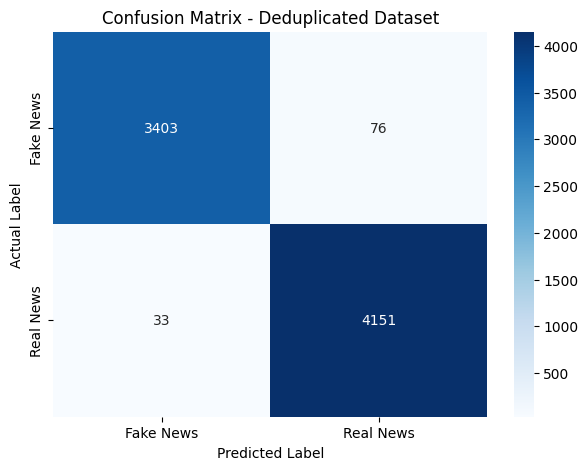

In [19]:

# Generate updated confusion matrix
cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News", "Real News"],
    yticklabels=["Fake News", "Real News"]
)

plt.title("Confusion Matrix - Deduplicated Dataset")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.savefig(
    "confusion_matrix_updated.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
